Little (971827, 6) ..\EMG Recordings\little_finger_30mins_combined.csv
Middle (1086342, 6) ..\EMG Recordings\middle_finger_30mins_combined.csv
Ring (994165, 6) ..\EMG Recordings\ring_finger_30mins_combined.csv
Index (1015193, 6) ..\EMG Recordings\index_finger_30mins_combined.csv
Thumb (966764, 6) ..\EMG Recordings\thumb_finger_30mins_combined.csv

Combined files created:

Little -> ..\EMG Recordings\little_finger_30mins_combined.csv
Middle -> ..\EMG Recordings\middle_finger_30mins_combined.csv
Ring -> ..\EMG Recordings\ring_finger_30mins_combined.csv
Index -> ..\EMG Recordings\index_finger_30mins_combined.csv
Thumb -> ..\EMG Recordings\thumb_finger_30mins_combined.csv
Little windows: 1819
Middle windows: 1944
Ring windows: 1868
Index windows: 1870
Thumb windows: 1813

Dataset Information
Features: (9314, 20)
Labels: (9314,)
Features per window: 20

Finger Distribution
Middle    1944
Index     1870
Ring      1868
Little    1819
Thumb     1813
Name: count, dtype: int64

Session Distribut

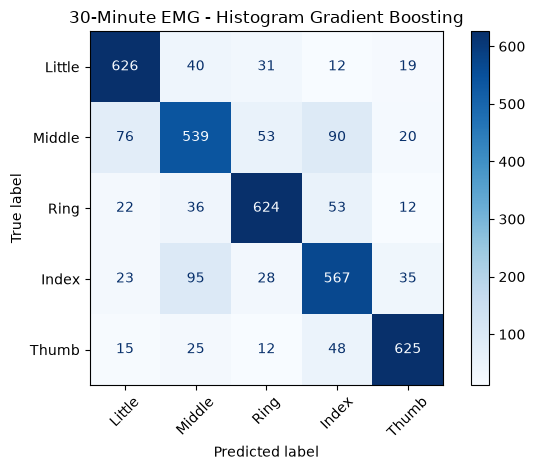

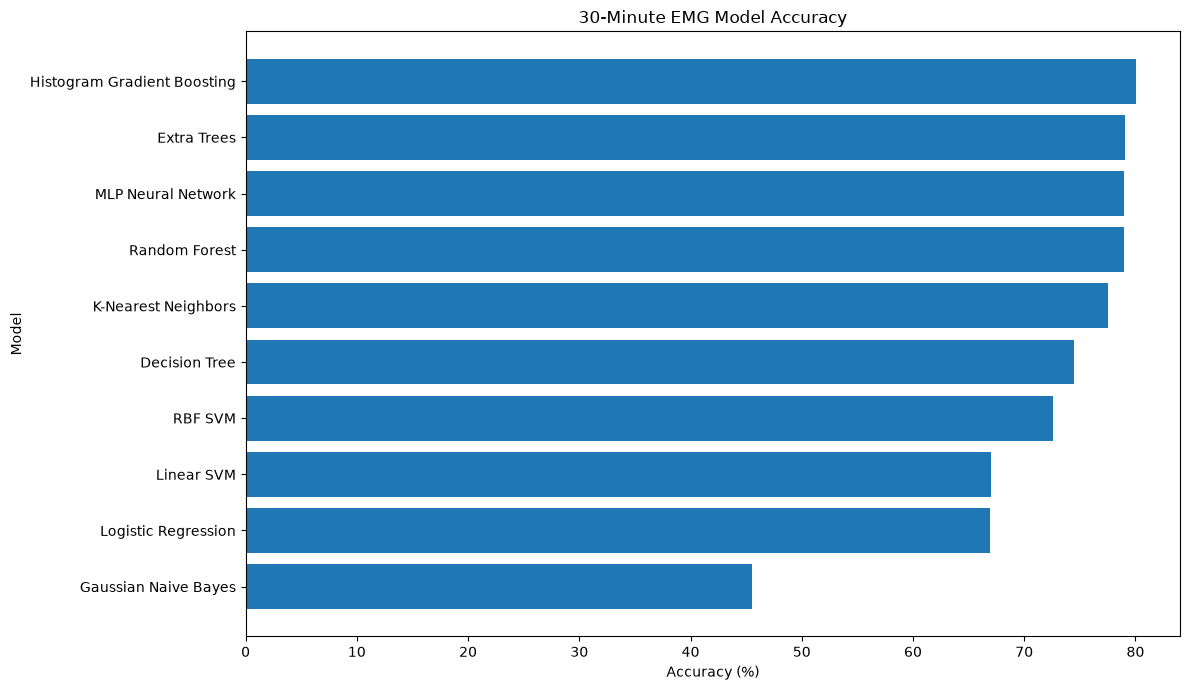

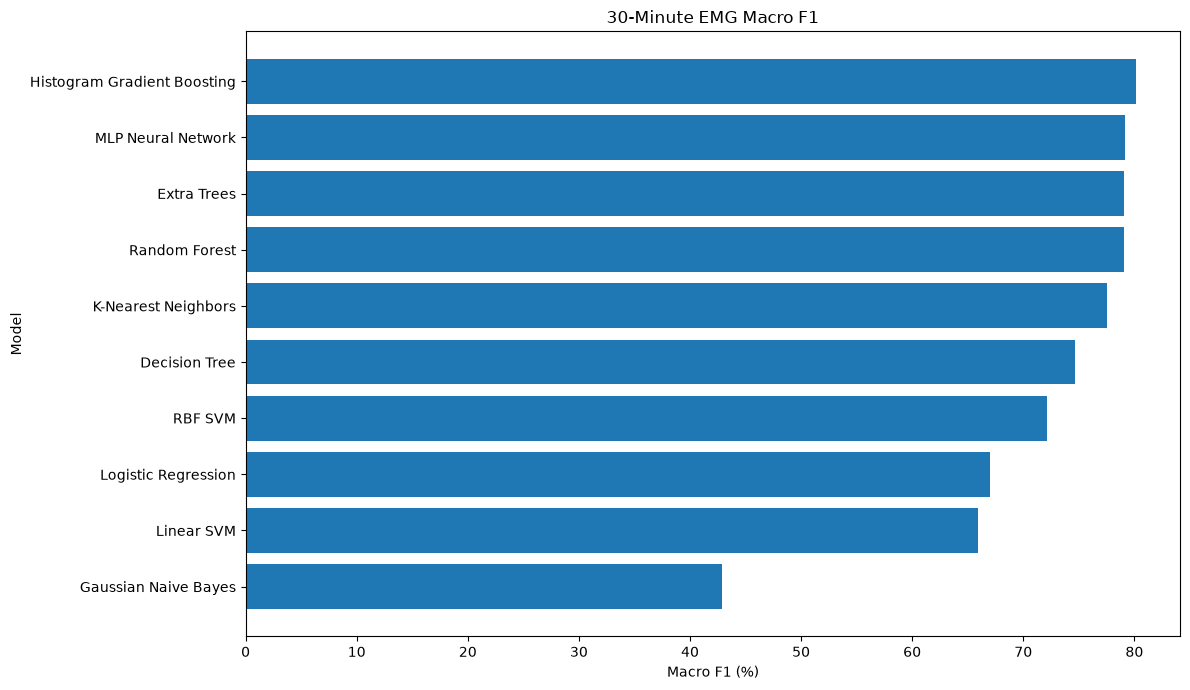


Random Window Predictions
Actual: Ring
Logistic Regression           Ring
K-Nearest Neighbors           Ring
RBF SVM                       Ring
Linear SVM                    Ring
Decision Tree                 Ring
Random Forest                 Ring
Extra Trees                   Ring
Histogram Gradient Boosting   Ring
Gaussian Naive Bayes          Ring
MLP Neural Network            Ring

Random Forest Feature Importance
                 Feature  Importance
    EMG1_Waveform_Length    0.099375
EMG1_Mean_Absolute_Value    0.092454
               EMG1_Mean    0.091971
            EMG1_Maximum    0.068562
              EMG1_Range    0.066451
             EMG1_Median    0.065066
    EMG2_Waveform_Length    0.060516
                EMG1_RMS    0.058846
 EMG1_Standard_Deviation    0.050095
           EMG1_Variance    0.048973
           EMG2_Variance    0.047513
 EMG2_Standard_Deviation    0.044314
                EMG2_RMS    0.041933
EMG2_Mean_Absolute_Value    0.039551
               EMG2_M

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import warnings

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

data_folder = Path("../EMG Recordings")


files = {
    "Little": {
        "5min": data_folder / "little finger emg_2sensor_20260922_123054.csv",
        "10min": data_folder / "little_finger 10mins.csv",
        "15min": data_folder / "little_finger_15mins.csv"
    },

    "Middle": {
        "5min": data_folder / "middle finger emg_2sensor_20260922_124337.csv",
        "10min": data_folder / "middle_finger_10mins.csv",
        "15min": data_folder / "middle_finger_15mins.csv"
    },

    "Ring": {
        "5min": data_folder / "Ring finger emg_2sensor_20260922_123712.csv",
        "10min": data_folder / "ring_finger_10mins.csv",
        "15min": data_folder / "ring_finger_15mins.csv"
    },

    "Index": {
        "5min": data_folder / "index emg_2sensor_20260922_124922.csv",
        "10min": data_folder / "index_finger_10mins.csv",
        "15min": data_folder / "index_finger_15mins.csv"
    },

    "Thumb": {
        "5min": data_folder / "Thumb finger emg_2sensor_20260922_125701.csv",
        "10min": data_folder / "thumb_finger_10mins.csv",
        "15min": data_folder / "thumb_finger_15mins.csv"
    }
}


combined_files = {}


for finger, session_files in files.items():

    combined_parts = []

    cumulative_time = 0.0

    for session_name in [
        "5min",
        "10min",
        "15min"
    ]:

        data = pd.read_csv(
            session_files[session_name]
        )

        data = data[
            [
                "time_s",
                "emg1",
                "emg2"
            ]
        ].copy()

        data["time_s"] = pd.to_numeric(
            data["time_s"],
            errors="coerce"
        )

        data["emg1"] = pd.to_numeric(
            data["emg1"],
            errors="coerce"
        )

        data["emg2"] = pd.to_numeric(
            data["emg2"],
            errors="coerce"
        )

        data = data.dropna().reset_index(
            drop=True
        )

        data["session"] = session_name

        data["session_time_s"] = (
            data["time_s"]
            -
            data["time_s"].iloc[0]
        )

        if len(data) > 1:

            time_differences = np.diff(
                data["session_time_s"].values
            )

            positive_differences = (
                time_differences[
                    time_differences > 0
                ]
            )

            if len(
                positive_differences
            ) > 0:

                time_step = np.median(
                    positive_differences
                )

            else:

                time_step = 0.001

        else:

            time_step = 0.001

        data["combined_time_s"] = (
            data["session_time_s"]
            +
            cumulative_time
        )

        cumulative_time = (
            data["combined_time_s"].iloc[-1]
            +
            time_step
        )

        combined_parts.append(
            data
        )


    combined_data = pd.concat(
        combined_parts,
        ignore_index=True
    )


    output_file = (
        data_folder
        /
        f"{finger.lower()}_finger_30mins_combined.csv"
    )


    combined_data.to_csv(
        output_file,
        index=False
    )


    combined_files[
        finger
    ] = output_file


    print(
        finger,
        combined_data.shape,
        output_file
    )


print("\nCombined files created:\n")


for finger, file_path in combined_files.items():

    print(
        finger,
        "->",
        file_path
    )


def calculate_statistics(values):

    values = np.asarray(
        values,
        dtype=float
    )

    mean_value = np.mean(
        values
    )

    median_value = np.median(
        values
    )

    minimum_value = np.min(
        values
    )

    maximum_value = np.max(
        values
    )

    standard_deviation = np.std(
        values
    )

    variance_value = np.var(
        values
    )

    value_range = (
        maximum_value
        -
        minimum_value
    )

    rms_value = np.sqrt(
        np.mean(
            values ** 2
        )
    )

    mean_absolute_value = np.mean(
        np.abs(
            values
        )
    )

    waveform_length = np.sum(
        np.abs(
            np.diff(
                values
            )
        )
    )


    return [
        mean_value,
        median_value,
        minimum_value,
        maximum_value,
        standard_deviation,
        variance_value,
        value_range,
        rms_value,
        mean_absolute_value,
        waveform_length
    ]


statistic_names = [
    "Mean",
    "Median",
    "Minimum",
    "Maximum",
    "Standard_Deviation",
    "Variance",
    "Range",
    "RMS",
    "Mean_Absolute_Value",
    "Waveform_Length"
]


feature_names = []


for statistic in statistic_names:

    feature_names.append(
        f"EMG1_{statistic}"
    )


for statistic in statistic_names:

    feature_names.append(
        f"EMG2_{statistic}"
    )


def create_time_windows(
    data,
    window_seconds=1.0
):

    features = []

    sessions = []


    for session_name in [
        "5min",
        "10min",
        "15min"
    ]:

        session_data = data[
            data["session"]
            ==
            session_name
        ].copy()


        if len(
            session_data
        ) == 0:

            continue


        session_data = session_data.sort_values(
            "session_time_s"
        )


        duration = session_data[
            "session_time_s"
        ].iloc[-1]


        number_of_windows = int(
            duration
            //
            window_seconds
        )


        for window_number in range(
            number_of_windows
        ):

            start_time = (
                window_number
                *
                window_seconds
            )

            end_time = (
                start_time
                +
                window_seconds
            )


            window = session_data[
                (
                    session_data["session_time_s"]
                    >=
                    start_time
                )
                &
                (
                    session_data["session_time_s"]
                    <
                    end_time
                )
            ]


            if len(
                window
            ) < 2:

                continue


            emg1_statistics = calculate_statistics(
                window["emg1"].values
            )


            emg2_statistics = calculate_statistics(
                window["emg2"].values
            )


            window_features = np.concatenate(
                [
                    emg1_statistics,
                    emg2_statistics
                ]
            )


            features.append(
                window_features
            )


            sessions.append(
                session_name
            )


    return (
        np.array(
            features
        ),
        np.array(
            sessions
        )
    )


emg_features = []

finger_labels = []

session_labels = []


for finger, file_path in combined_files.items():

    data = pd.read_csv(
        file_path
    )


    finger_features, finger_sessions = (
        create_time_windows(
            data,
            window_seconds=1.0
        )
    )


    print(
        finger,
        "windows:",
        len(
            finger_features
        )
    )


    for feature_vector, session_name in zip(
        finger_features,
        finger_sessions
    ):

        emg_features.append(
            feature_vector
        )

        finger_labels.append(
            finger
        )

        session_labels.append(
            session_name
        )


emg_features = np.array(
    emg_features
)

finger_labels = np.array(
    finger_labels
)

session_labels = np.array(
    session_labels
)


print("\nDataset Information")

print(
    "Features:",
    emg_features.shape
)

print(
    "Labels:",
    finger_labels.shape
)

print(
    "Features per window:",
    emg_features.shape[1]
)


print("\nFinger Distribution")

print(
    pd.Series(
        finger_labels
    ).value_counts()
)


print("\nSession Distribution")

print(
    pd.Series(
        session_labels
    ).value_counts()
)


(
    train_features,
    test_features,
    train_labels,
    test_labels,
    train_sessions,
    test_sessions

) = train_test_split(

    emg_features,
    finger_labels,
    session_labels,

    train_size=0.60,

    test_size=0.40,

    random_state=42,

    shuffle=True,

    stratify=finger_labels
)


print(
    "\nTraining:",
    train_features.shape
)

print(
    "Testing:",
    test_features.shape
)


print(
    "\nTraining sessions:"
)

print(
    pd.Series(
        train_sessions
    ).value_counts()
)


print(
    "\nTesting sessions:"
)

print(
    pd.Series(
        test_sessions
    ).value_counts()
)


random_index = np.random.randint(
    0,
    len(
        test_features
    )
)


random_features = test_features[
    random_index
]

random_label = test_labels[
    random_index
]

random_session = test_sessions[
    random_index
]


print("\nRandom Test Window")

print(
    "Finger:",
    random_label
)

print(
    "Session:",
    random_session
)


print(
    f"\n{'Statistic':<25}"
    f"{'EMG1':>15}"
    f"{'EMG2':>15}"
)


for i in range(
    len(
        statistic_names
    )
):

    print(
        f"{statistic_names[i]:<25}"
        f"{random_features[i]:>15.4f}"
        f"{random_features[i + 10]:>15.4f}"
    )


models = {

    "Logistic Regression":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LogisticRegression(
                    max_iter=3000,
                    random_state=42
                )
            )
        ]),


    "K-Nearest Neighbors":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                KNeighborsClassifier(
                    n_neighbors=7,
                    weights="distance",
                    n_jobs=-1
                )
            )
        ]),


    "RBF SVM":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                SVC(
                    kernel="rbf",
                    C=3.0,
                    gamma="scale"
                )
            )
        ]),


    "Linear SVM":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LinearSVC(
                    C=1.0,
                    max_iter=5000,
                    random_state=42
                )
            )
        ]),


    "Decision Tree":

        DecisionTreeClassifier(
            min_samples_leaf=2,
            random_state=42
        ),


    "Random Forest":

        RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ),


    "Extra Trees":

        ExtraTreesClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ),


    "Histogram Gradient Boosting":

        HistGradientBoostingClassifier(
            max_iter=300,
            learning_rate=0.08,
            max_leaf_nodes=31,
            random_state=42
        ),


    "Gaussian Naive Bayes":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                GaussianNB()
            )
        ]),


    "MLP Neural Network":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                MLPClassifier(
                    hidden_layer_sizes=(
                        128,
                        64
                    ),
                    activation="relu",
                    solver="adam",
                    learning_rate_init=0.001,
                    max_iter=500,
                    early_stopping=True,
                    validation_fraction=0.10,
                    n_iter_no_change=20,
                    random_state=42
                )
            )
        ])
}


results = []

trained_models = {}

model_predictions = {}


print("\nTraining 10 Models")


for model_number, (
    model_name,
    model
) in enumerate(
    models.items(),
    start=1
):

    print(
        f"\n[{model_number}/10] "
        f"{model_name}"
    )


    try:

        training_start = time.perf_counter()


        model.fit(
            train_features,
            train_labels
        )


        training_time = (
            time.perf_counter()
            -
            training_start
        )


        prediction_start = time.perf_counter()


        predictions = model.predict(
            test_features
        )


        prediction_time = (
            time.perf_counter()
            -
            prediction_start
        )


        accuracy = accuracy_score(
            test_labels,
            predictions
        )


        balanced_accuracy = (
            balanced_accuracy_score(
                test_labels,
                predictions
            )
        )


        precision = precision_score(
            test_labels,
            predictions,
            average="macro",
            zero_division=0
        )


        recall = recall_score(
            test_labels,
            predictions,
            average="macro",
            zero_division=0
        )


        macro_f1 = f1_score(
            test_labels,
            predictions,
            average="macro",
            zero_division=0
        )


        weighted_f1 = f1_score(
            test_labels,
            predictions,
            average="weighted",
            zero_division=0
        )


        results.append(
            {
                "Model":
                    model_name,

                "Accuracy":
                    accuracy,

                "Balanced Accuracy":
                    balanced_accuracy,

                "Macro Precision":
                    precision,

                "Macro Recall":
                    recall,

                "Macro F1":
                    macro_f1,

                "Weighted F1":
                    weighted_f1,

                "Training Time":
                    training_time,

                "Prediction Time":
                    prediction_time
            }
        )


        trained_models[
            model_name
        ] = model


        model_predictions[
            model_name
        ] = predictions


        print(
            f"Accuracy: "
            f"{accuracy * 100:.2f}%"
        )


        print(
            f"Macro F1: "
            f"{macro_f1 * 100:.2f}%"
        )


        print(
            f"Training time: "
            f"{training_time:.2f}s"
        )


    except Exception as error:

        print(
            "FAILED:",
            error
        )


results = pd.DataFrame(
    results
)


results = results.sort_values(
    by=[
        "Accuracy",
        "Macro F1"
    ],
    ascending=False
).reset_index(
    drop=True
)


results.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(
            results
        ) + 1
    )
)


display_results = results.copy()


percentage_columns = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]


for column in percentage_columns:

    display_results[
        column
    ] *= 100


print("\n")
print("=" * 120)

print(
    "30-MINUTE EMG MODEL COMPARISON"
)

print("=" * 120)


print(
    display_results.to_string(
        index=False,
        float_format=lambda value:
            f"{value:.4f}"
    )
)


results.to_csv(
    "30min_10_model_comparison.csv",
    index=False
)


best_model_name = results.iloc[
    0
]["Model"]


best_model = trained_models[
    best_model_name
]


best_predictions = model_predictions[
    best_model_name
]


print("\nBest Model")

print(
    best_model_name
)

print(
    f"Accuracy: "
    f"{results.iloc[0]['Accuracy'] * 100:.4f}%"
)

print(
    f"Macro F1: "
    f"{results.iloc[0]['Macro F1'] * 100:.4f}%"
)


print("\nClassification Report\n")


print(
    classification_report(
        test_labels,
        best_predictions,
        digits=4,
        zero_division=0
    )
)


finger_names = [
    "Little",
    "Middle",
    "Ring",
    "Index",
    "Thumb"
]


matrix = confusion_matrix(
    test_labels,
    best_predictions,
    labels=finger_names
)


display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=finger_names
)


display.plot(
    cmap="Blues"
)


plt.title(
    f"30-Minute EMG - {best_model_name}"
)


plt.xticks(
    rotation=45
)


plt.tight_layout()


plt.show()


plot_results = results.sort_values(
    "Accuracy",
    ascending=True
)


plt.figure(
    figsize=(
        12,
        7
    )
)


plt.barh(
    plot_results["Model"],
    plot_results["Accuracy"]
    *
    100
)


plt.xlabel(
    "Accuracy (%)"
)


plt.ylabel(
    "Model"
)


plt.title(
    "30-Minute EMG Model Accuracy"
)


plt.tight_layout()


plt.show()


plot_results = results.sort_values(
    "Macro F1",
    ascending=True
)


plt.figure(
    figsize=(
        12,
        7
    )
)


plt.barh(
    plot_results["Model"],
    plot_results["Macro F1"]
    *
    100
)


plt.xlabel(
    "Macro F1 (%)"
)


plt.ylabel(
    "Model"
)


plt.title(
    "30-Minute EMG Macro F1"
)


plt.tight_layout()


plt.show()


print("\nRandom Window Predictions")

print(
    "Actual:",
    random_label
)


for model_name, model in trained_models.items():

    prediction = model.predict(
        random_features.reshape(
            1,
            -1
        )
    )[0]


    print(
        f"{model_name:<30}"
        f"{prediction}"
    )


random_forest = trained_models.get(
    "Random Forest"
)


if random_forest is not None:

    importance = pd.DataFrame(
        {
            "Feature":
                feature_names,

            "Importance":
                random_forest.feature_importances_
        }
    )


    importance = importance.sort_values(
        "Importance",
        ascending=False
    ).reset_index(
        drop=True
    )


    print(
        "\nRandom Forest Feature Importance"
    )


    print(
        importance.to_string(
            index=False
        )
    )


    importance.to_csv(
        "30min_random_forest_feature_importance.csv",
        index=False
    )


print("\n")

print("FINAL SUMMARY")



print(
    "Total windows:",
    len(
        emg_features
    )
)


print(
    "Training windows:",
    len(
        train_features
    )
)


print(
    "Testing windows:",
    len(
        test_features
    )
)


print(
    "Features per window:",
    emg_features.shape[1]
)


print(
    "Best model:",
    best_model_name
)


print(
    f"Best accuracy: "
    f"{results.iloc[0]['Accuracy'] * 100:.4f}%"
)


print(
    f"Best Macro F1: "
    f"{results.iloc[0]['Macro F1'] * 100:.4f}%"
)